# Fixed Hospital Split: Feature Selection vs Cross-Hospital Generalization

## Question
Holding the **outcome, hospital split, model, preprocessing, and metric fixed**, how does the
**feature-selection method** change cross-hospital generalization?

Protocol:
1. Fix source hospitals and held-out hospitals using a hospital attribute.
2. Split source-hospital patient rows 80/20, keeping the same hospitals in both subsets.
3. Select features using the 80% source-train rows only.
4. Train the same logistic-regression model for every feature set.
5. Evaluate internal AUROC on the 20% source validation rows and AUROC separately at each held-out hospital.
6. Define `gap = internal AUROC - held-out hospital AUROC`.
7. Compare the gap distribution across feature-selection methods.

### Primary defaults
- **Outcome:** `label_J96.00` (future respiratory failure after the first 24-hour feature window).
- **Source hospitals:** Midwest.
- **Held-out hospitals:** Northeast hospitals meeting minimum sample-size and class-count thresholds.
- **Primary metric:** AUROC; AUPRC and Brier are secondary.

These defaults are based on prior full-data work: `label_J96.00` gave clearer hospital-to-hospital
differences than mortality, and region-based transfer produced meaningful gaps. The split is fixed
before comparing feature selectors.

### Feature-selection methods
1. All eligible features (control).
2. Top pooled predictive utility.
3. L1 logistic-regression ranking.
4. Cross-site consensus (OHDSI-inspired proxy).
5. StableMate-inspired predictive-then-stable ranking.
6. Project score: `utility - lambda * instability`.

The OHDSI- and StableMate-inspired methods are **proxies**, not exact reproductions.

In [1]:
from pathlib import Path
import pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
# Primary experiment
OUTCOME = "label_J96.00"
TRAIN_REGION = "Midwest"
TEST_REGION = "Northeast"
INTERNAL_VALIDATION_FRACTION = 0.20

# Held-out hospital eligibility
MIN_TEST_HOSPITAL_N = 300
MIN_TEST_POSITIVES = 15
MIN_TEST_NEGATIVES = 15

# Source hospitals used for stability calculations
MIN_SOURCE_ENV_N = 150
MIN_SOURCE_ENV_POSITIVES = 5
MIN_SOURCE_ENV_NEGATIVES = 5

# Source-only candidate filtering
MIN_FEATURE_NONMISSING_RATE = 0.05
MIN_FEATURE_NONMISSING_COUNT = 500
MIN_SOURCE_HOSPITALS_WITH_FEATURE = 5
MIN_OBS_PER_HOSPITAL_FOR_FEATURE = 30
MAX_FEATURES_PER_GROUP = 40
MAX_TOTAL_CANDIDATES = 160

# Keep feature count fixed for selector comparisons
N_SELECTED = 30

L1_C = 0.05
STABLEMATE_PREDICTIVE_POOL = 60
UTILITY_INSTABILITY_LAMBDA = 0.50
FINAL_MODEL_C = 0.10

OUTPUT_DIR = Path("feature_selection_generalization_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the full processed eICU data

In [3]:
def find_project_data(filename):
    cwd = Path.cwd().resolve()
    candidates = []
    for base in [cwd, *list(cwd.parents)[:6]]:
        candidates.append(base / "data" / filename)
    candidates += [
        (cwd / "../../data" / filename).resolve(),
        (cwd / "../../../data" / filename).resolve(),
    ]
    seen = set()
    for p in candidates:
        p = p.resolve()
        if p in seen:
            continue
        seen.add(p)
        if p.exists():
            return p
    tried = "\n".join(f"  - {p}" for p in seen)
    raise FileNotFoundError(f"Could not find {filename}. Tried:\n{tried}")

DATA_PATH = find_project_data("clean_dataset.parquet")
FEATURE_NAMES_PATH = find_project_data("feature_names.pkl")

feature_sets = pickle.load(open(FEATURE_NAMES_PATH, "rb"))
patient_agg = pd.read_parquet(DATA_PATH)

if "age" in patient_agg.columns:
    patient_agg.loc[patient_agg["age"] == "> 89", "age"] = "90"
    patient_agg["age"] = pd.to_numeric(patient_agg["age"], errors="coerce")

if OUTCOME not in patient_agg.columns:
    raise KeyError(f"{OUTCOME!r} is not in the dataset.")

patient_agg[OUTCOME] = patient_agg[OUTCOME].fillna(0).astype(int)

print("Data:", DATA_PATH)
print("Shape:", patient_agg.shape)
print(f"{OUTCOME} prevalence: {patient_agg[OUTCOME].mean():.3%}")

Data: /Users/gabrielarm300/data/clean_dataset.parquet
Shape: (135778, 2167)
label_J96.00 prevalence: 9.348%


## 2. Define candidate features and lock the hospital split

In [4]:
labs = [c for c in feature_sets["labs"].tolist() if c in patient_agg.columns]
vitals = [c for c in feature_sets["vitals"].tolist() if c in patient_agg.columns]
icd = [c for c in feature_sets["icd10_before24h"].tolist() if c in patient_agg.columns]
admissiondx = [c for c in feature_sets["admissiondx"].tolist() if c in patient_agg.columns]
demographic_numeric = [c for c in ["age", "admissionheight", "admissionweight"] if c in patient_agg.columns]

raw_feature_group = {}
for c in labs: raw_feature_group[c] = "labs"
for c in vitals: raw_feature_group[c] = "vitals"
for c in icd: raw_feature_group[c] = "icd10_before24h"
for c in admissiondx: raw_feature_group[c] = "admissiondx"
for c in demographic_numeric: raw_feature_group[c] = "demographic"

raw_candidates = list(dict.fromkeys(labs + vitals + icd + admissiondx + demographic_numeric))
raw_candidates = [
    c for c in raw_candidates
    if "J96" not in c.upper()
    and not c.startswith("label_")
    and c not in {"hospitalid", "hospital_region", "hospital_numbedscategory"}
]

for c in raw_candidates:
    patient_agg[c] = pd.to_numeric(patient_agg[c], errors="coerce")

hospital_stats = (
    patient_agg.groupby("hospitalid")
    .agg(
        n=("hospitalid", "size"),
        positives=(OUTCOME, "sum"),
        prevalence=(OUTCOME, "mean"),
        region=("hospital_region", "first"),
    )
)
hospital_stats["negatives"] = hospital_stats["n"] - hospital_stats["positives"]

train_hospital_ids = hospital_stats.index[hospital_stats["region"].eq(TRAIN_REGION)].tolist()
test_hospital_ids = hospital_stats.index[
    hospital_stats["region"].eq(TEST_REGION)
    & (hospital_stats["n"] >= MIN_TEST_HOSPITAL_N)
    & (hospital_stats["positives"] >= MIN_TEST_POSITIVES)
    & (hospital_stats["negatives"] >= MIN_TEST_NEGATIVES)
].tolist()

if len(train_hospital_ids) < 2 or len(test_hospital_ids) < 2:
    raise ValueError("Too few hospitals for the configured regional split.")

source_all = patient_agg[patient_agg["hospitalid"].isin(train_hospital_ids)].copy()
test_all = patient_agg[patient_agg["hospitalid"].isin(test_hospital_ids)].copy()

study_hospitals = len(train_hospital_ids) + len(test_hospital_ids)
print(f"TRAIN: {TRAIN_REGION}: {len(train_hospital_ids)} hospitals, {len(source_all):,} patients, prevalence={source_all[OUTCOME].mean():.3%}")
print(f"TEST:  {TEST_REGION}: {len(test_hospital_ids)} eligible hospitals, {len(test_all):,} patients, prevalence={test_all[OUTCOME].mean():.3%}")
print(f"Hospital split in this two-region cohort: {len(train_hospital_ids)/study_hospitals:.1%} train / {len(test_hospital_ids)/study_hospitals:.1%} test")
display(hospital_stats.loc[test_hospital_ids].sort_values("n", ascending=False))

TRAIN: Midwest: 70 hospitals, 47,108 patients, prevalence=5.422%
TEST:  Northeast: 8 eligible hospitals, 8,426 patients, prevalence=21.256%
Hospital split in this two-region cohort: 89.7% train / 10.3% test


,n,positives,prevalence,region,negatives
hospitalid,,,,,
420,3293,1211,0.367750,Northeast,2082
199,2323,155,0.066724,Northeast,2168
202,673,37,0.054978,Northeast,636
206,662,55,0.083082,Northeast,607
421,457,130,0.284464,Northeast,327
419,383,82,0.214099,Northeast,301
424,329,92,0.279635,Northeast,237
200,306,29,0.094771,Northeast,277


## 3. Fixed 80/20 patient split within source hospitals

In [5]:
source_train, source_internal = train_test_split(
    source_all,
    test_size=INTERNAL_VALIDATION_FRACTION,
    random_state=SEED,
    stratify=source_all[OUTCOME],
)
source_train = source_train.copy()
source_internal = source_internal.copy()

print("source_train:", source_train.shape, "hospitals:", source_train["hospitalid"].nunique())
print("source_internal:", source_internal.shape, "hospitals:", source_internal["hospitalid"].nunique())

source_train: (37686, 2167) hospitals: 70
source_internal: (9422, 2167) hospitals: 68


## 4. Source-only candidate quality filter

In [6]:
def build_candidate_pool(df):
    rows = []
    for feature in raw_candidates:
        x = pd.to_numeric(df[feature], errors="coerce")
        nonmissing = int(x.notna().sum())
        nonmissing_rate = float(x.notna().mean())
        nunique = int(x.nunique(dropna=True))
        per_hosp_obs = x.notna().groupby(df["hospitalid"]).sum()
        hosp_coverage = int((per_hosp_obs >= MIN_OBS_PER_HOSPITAL_FOR_FEATURE).sum())

        if (
            nonmissing >= MIN_FEATURE_NONMISSING_COUNT
            and nonmissing_rate >= MIN_FEATURE_NONMISSING_RATE
            and hosp_coverage >= MIN_SOURCE_HOSPITALS_WITH_FEATURE
            and nunique > 1
        ):
            rows.append({
                "feature": feature,
                "feature_group": raw_feature_group.get(feature, "other"),
                "nonmissing": nonmissing,
                "nonmissing_rate": nonmissing_rate,
                "hospital_coverage": hosp_coverage,
                "nunique": nunique,
            })

    coverage = pd.DataFrame(rows)
    if coverage.empty:
        raise ValueError("No features survived the source-only coverage filter.")

    pieces = []
    for group, g in coverage.groupby("feature_group"):
        pieces.append(
            g.sort_values(["hospital_coverage", "nonmissing"], ascending=False)
             .head(MAX_FEATURES_PER_GROUP)
        )

    kept = pd.concat(pieces, ignore_index=True)
    kept = kept.sort_values(["hospital_coverage", "nonmissing"], ascending=False).head(MAX_TOTAL_CANDIDATES)
    return kept.reset_index(drop=True)

candidate_table = build_candidate_pool(source_train)
candidate_features = candidate_table["feature"].tolist()

print("Candidate features:", len(candidate_features))
display(candidate_table.groupby("feature_group").size().rename("n_features"))

Candidate features: 151


feature_group
admissiondx        40
demographic         3
icd10_before24h    40
labs               40
vitals             28
Name: n_features, dtype: int64

## 5. Predictive utility and cross-hospital instability

All scores below use **source-train only**.

- Predictive utility = `2 * abs(univariate AUROC - 0.5)`.
- Missingness instability = SD of hospital-level observation rates.
- Distribution instability = leave-one-hospital-out KS shift (continuous) or prevalence shift (binary).
- Relationship instability = SD of signed per-hospital AUROC (`AUC - 0.5`).

In [7]:
def feature_kind(series):
    vals = pd.to_numeric(series, errors="coerce").dropna().unique()
    if len(vals) <= 2 and set(np.unique(vals)).issubset({0, 1}):
        return "binary"
    return "continuous"

def pooled_utility(feature, df):
    x = pd.to_numeric(df[feature], errors="coerce")
    y = df[OUTCOME]
    mask = x.notna()
    if mask.sum() < MIN_FEATURE_NONMISSING_COUNT or y[mask].nunique() < 2:
        return np.nan, np.nan
    auc = roc_auc_score(y[mask], x[mask])
    return auc, 2 * abs(auc - 0.5)

source_env_stats = source_train.groupby("hospitalid")[OUTCOME].agg(["count", "sum"])
source_env_stats["negatives"] = source_env_stats["count"] - source_env_stats["sum"]

stability_hospitals = source_env_stats.index[
    (source_env_stats["count"] >= MIN_SOURCE_ENV_N)
    & (source_env_stats["sum"] >= MIN_SOURCE_ENV_POSITIVES)
    & (source_env_stats["negatives"] >= MIN_SOURCE_ENV_NEGATIVES)
].tolist()

print("Source hospitals usable for hospital-level stability:", len(stability_hospitals))

Source hospitals usable for hospital-level stability: 46


In [8]:
def compute_feature_scores(df, features):
    rows = []

    for i, feature in enumerate(features, start=1):
        x = pd.to_numeric(df[feature], errors="coerce")
        y = df[OUTCOME]
        kind = feature_kind(x)
        pooled_auc, utility = pooled_utility(feature, df)

        observed_rates = x.notna().groupby(df["hospitalid"]).mean()
        miss_inst = float(observed_rates.std(ddof=0))

        dist_scores = []
        rel_effects = []

        for h in stability_hospitals:
            hmask = df["hospitalid"].eq(h)
            x_h = x[hmask].dropna()
            x_other = x[~hmask].dropna()

            if len(x_h) >= MIN_OBS_PER_HOSPITAL_FOR_FEATURE and len(x_other) >= MIN_OBS_PER_HOSPITAL_FOR_FEATURE:
                if kind == "binary":
                    dist_scores.append(abs(float(x_h.mean()) - float(x_other.mean())))
                else:
                    a, b = x_h.to_numpy(), x_other.to_numpy()
                    if len(a) > 750: a = rng.choice(a, 750, replace=False)
                    if len(b) > 3000: b = rng.choice(b, 3000, replace=False)
                    dist_scores.append(ks_2samp(a, b, mode="auto").statistic)

            pair = hmask & x.notna()
            yh = y[pair]
            xh = x[pair]
            if (
                len(xh) >= MIN_SOURCE_ENV_N
                and yh.nunique() == 2
                and yh.sum() >= MIN_SOURCE_ENV_POSITIVES
                and (len(yh) - yh.sum()) >= MIN_SOURCE_ENV_NEGATIVES
            ):
                rel_effects.append(roc_auc_score(yh, xh) - 0.5)

        dist_inst = float(np.mean(dist_scores)) if len(dist_scores) >= MIN_SOURCE_HOSPITALS_WITH_FEATURE else np.nan
        rel_inst = float(np.std(rel_effects, ddof=0)) if len(rel_effects) >= MIN_SOURCE_HOSPITALS_WITH_FEATURE else np.nan

        rows.append({
            "feature": feature,
            "feature_group": raw_feature_group.get(feature, "other"),
            "predictive_utility": utility,
            "pooled_auc": pooled_auc,
            "missingness_instability": miss_inst,
            "distribution_instability": dist_inst,
            "relationship_instability": rel_inst,
            "n_relationship_hospitals": len(rel_effects),
        })

        if i % 25 == 0 or i == len(features):
            print(f"Scored {i}/{len(features)}")

    scores = pd.DataFrame(rows)

    for col in ["predictive_utility", "missingness_instability", "distribution_instability", "relationship_instability"]:
        scores[col + "_rank"] = scores[col].rank(pct=True, method="average")

    inst_rank_cols = [
        "missingness_instability_rank",
        "distribution_instability_rank",
        "relationship_instability_rank",
    ]
    complete = scores[inst_rank_cols].notna().all(axis=1)
    scores["combined_instability"] = np.nan
    scores.loc[complete, "combined_instability"] = scores.loc[complete, inst_rank_cols].mean(axis=1)

    valid = scores["predictive_utility_rank"].notna() & scores["combined_instability"].notna()
    scores["utility_instability_score"] = np.nan
    scores.loc[valid, "utility_instability_score"] = (
        scores.loc[valid, "predictive_utility_rank"]
        - UTILITY_INSTABILITY_LAMBDA * scores.loc[valid, "combined_instability"]
    )
    return scores

feature_scores = compute_feature_scores(source_train, candidate_features)
display(feature_scores.sort_values("predictive_utility", ascending=False).head(15))

Scored 25/151
Scored 50/151
Scored 75/151
Scored 100/151
Scored 125/151
Scored 150/151
Scored 151/151


,feature,feature_group,predictive_utility,pooled_auc,missingness_instability,distribution_instability,relationship_instability,n_relationship_hospitals,predictive_utility_rank,missingness_instability_rank,distribution_instability_rank,relationship_instability_rank,combined_instability,utility_instability_score
142,systemicsystolic_bin1,vitals,0.219301,0.390350,0.114490,0.133781,0.054560,12,1.000000,0.410596,0.854305,0.544218,0.603039,0.698480
133,FiO2,labs,0.215001,0.607501,0.178675,0.284568,0.074642,23,0.993377,0.814570,0.986755,0.748299,0.849875,0.568440
103,lymphs,labs,0.211775,0.394113,0.216820,0.079130,0.078151,43,0.986755,0.900662,0.629139,0.816327,0.782043,0.595734
147,cvp_bin1,vitals,0.203734,0.601867,0.065207,0.179666,NaN,3,0.980132,0.284768,0.966887,NaN,NaN,NaN
116,AST (SGOT),labs,0.187047,0.593524,0.210120,0.108710,0.083125,41,0.973510,0.880795,0.728477,0.877551,0.828941,0.559040
141,systemicmean_bin1,vitals,0.186583,0.406709,0.114782,0.126649,0.062623,12,0.966887,0.423841,0.801325,0.585034,0.603400,0.665187
122,polys,labs,0.178918,0.589459,0.327591,0.088304,0.076515,36,0.960265,0.953642,0.662252,0.782313,0.799402,0.560564
108,sao2_bin2,vitals,0.165836,0.582918,0.110746,0.127730,0.136354,38,0.953642,0.403974,0.814570,1.000000,0.739514,0.583885
107,heartrate_bin2,vitals,0.161658,0.580829,0.094319,0.066547,0.071986,39,0.947020,0.377483,0.562914,0.687075,0.542491,0.675775
113,eos,labs,0.157109,0.421445,0.235029,0.161242,0.057224,41,0.940397,0.927152,0.927152,0.551020,0.801775,0.539510


## 6. Feature-selection methods

In [9]:
def select_top_utility(scores, k):
    return (
        scores.dropna(subset=["predictive_utility"])
        .sort_values("predictive_utility", ascending=False)
        .head(k)["feature"].tolist()
    )

def select_l1(df, features, k):
    X = df[features].apply(pd.to_numeric, errors="coerce")
    y = df[OUTCOME].astype(int)
    imp = SimpleImputer(strategy="median")
    scale = StandardScaler()
    Xs = scale.fit_transform(imp.fit_transform(X))
    m = LogisticRegression(
        penalty="l1", solver="liblinear", C=L1_C,
        class_weight="balanced", max_iter=2000, random_state=SEED
    ).fit(Xs, y)
    ranking = pd.Series(np.abs(m.coef_[0]), index=features, name="abs_l1_coef").sort_values(ascending=False)
    return ranking.head(k).index.tolist(), ranking

def build_cross_site_consensus(df, features, k):
    counts = pd.Series(0.0, index=features)
    used = 0
    for h in stability_hospitals:
        hdf = df[df["hospitalid"].eq(h)]
        y = hdf[OUTCOME]
        if y.nunique() != 2:
            continue
        vals = []
        for feature in features:
            x = pd.to_numeric(hdf[feature], errors="coerce")
            mask = x.notna()
            if mask.sum() < MIN_OBS_PER_HOSPITAL_FOR_FEATURE or y[mask].nunique() != 2:
                continue
            auc = roc_auc_score(y[mask], x[mask])
            vals.append((feature, 2 * abs(auc - 0.5)))
        if not vals:
            continue
        used += 1
        for feature, _ in sorted(vals, key=lambda t: t[1], reverse=True)[:k]:
            counts.loc[feature] += 1

    if used == 0:
        raise ValueError("No source hospitals usable for consensus selector.")

    consensus = (counts / used).rename("consensus_frequency")
    pooled = feature_scores.set_index("feature")["predictive_utility"]
    ranking = pd.concat([consensus, pooled], axis=1).sort_values(
        ["consensus_frequency", "predictive_utility"], ascending=False
    )
    return ranking.head(k).index.tolist(), ranking

def select_stablemate_proxy(scores, k):
    pool = (
        scores.dropna(subset=["predictive_utility", "relationship_instability"])
        .sort_values("predictive_utility", ascending=False)
        .head(min(STABLEMATE_PREDICTIVE_POOL, len(scores)))
        .copy()
    )
    pool = pool.sort_values(["relationship_instability", "predictive_utility"], ascending=[True, False])
    return pool.head(k)["feature"].tolist(), pool

def select_utility_instability(scores, k):
    ranking = scores.dropna(subset=["utility_instability_score"]).sort_values(
        "utility_instability_score", ascending=False
    )
    return ranking.head(k)["feature"].tolist(), ranking

top_utility = select_top_utility(feature_scores, N_SELECTED)
l1_features, l1_ranking = select_l1(source_train, candidate_features, N_SELECTED)
consensus_features, consensus_ranking = build_cross_site_consensus(source_train, candidate_features, N_SELECTED)
stablemate_features, stablemate_ranking = select_stablemate_proxy(feature_scores, N_SELECTED)
utility_instability_features, utility_instability_ranking = select_utility_instability(feature_scores, N_SELECTED)

selected_feature_sets = {
    "all_eligible": candidate_features,
    f"top{N_SELECTED}_utility": top_utility,
    f"top{N_SELECTED}_l1": l1_features,
    f"top{N_SELECTED}_cross_site_consensus": consensus_features,
    f"top{N_SELECTED}_stablemate_proxy": stablemate_features,
    f"top{N_SELECTED}_utility_minus_instability": utility_instability_features,
}

for name, feats in selected_feature_sets.items():
    print(f"{name:40s} {len(feats):3d}")

/Users/gabrielarm300/miniconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


all_eligible                             151
top30_utility                             30
top30_l1                                  30
top30_cross_site_consensus                30
top30_stablemate_proxy                    30
top30_utility_minus_instability           30


In [10]:
selection_rows = []
for method, feats in selected_feature_sets.items():
    for rank, feature in enumerate(feats, start=1):
        selection_rows.append({
            "method": method,
            "rank": rank,
            "feature": feature,
            "feature_group": raw_feature_group.get(feature, "other"),
        })

selection_table = pd.DataFrame(selection_rows)
group_counts = selection_table.groupby(["method", "feature_group"]).size().unstack(fill_value=0)
display(group_counts)

selection_table.to_csv(OUTPUT_DIR / "selected_features_by_method.csv", index=False)
feature_scores.to_csv(OUTPUT_DIR / "source_feature_scores.csv", index=False)

feature_group,admissiondx,demographic,icd10_before24h,labs,vitals
method,,,,,
all_eligible,40,3,40,40,28
top30_cross_site_consensus,0,0,0,18,12
top30_l1,7,1,1,14,7
top30_stablemate_proxy,1,1,1,16,11
top30_utility,0,0,1,15,14
top30_utility_minus_instability,0,0,1,14,15


## 7. Train the identical final model for every selected feature set

In [11]:
def make_final_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            C=FINAL_MODEL_C,
            max_iter=2500,
            class_weight="balanced",
            random_state=SEED,
        )),
    ])

def evaluate_method(method, features):
    model = make_final_model()
    Xtr = source_train[features].apply(pd.to_numeric, errors="coerce")
    ytr = source_train[OUTCOME].astype(int)
    Xint = source_internal[features].apply(pd.to_numeric, errors="coerce")
    yint = source_internal[OUTCOME].astype(int)

    model.fit(Xtr, ytr)
    pint = model.predict_proba(Xint)[:, 1]
    int_auc = roc_auc_score(yint, pint)
    int_pr = average_precision_score(yint, pint)
    int_brier = brier_score_loss(yint, pint)

    rows = [{
        "method": method, "evaluation": "internal", "hospitalid": "internal",
        "n": len(yint), "positives": int(yint.sum()), "prevalence": float(yint.mean()),
        "auroc": int_auc, "auprc": int_pr, "brier": int_brier,
        "gap_auroc": 0.0, "n_features": len(features),
    }]

    for h in sorted(test_hospital_ids):
        hdf = test_all[test_all["hospitalid"].eq(h)]
        yh = hdf[OUTCOME].astype(int)
        if yh.nunique() != 2:
            continue
        Xh = hdf[features].apply(pd.to_numeric, errors="coerce")
        ph = model.predict_proba(Xh)[:, 1]
        auc = roc_auc_score(yh, ph)
        rows.append({
            "method": method, "evaluation": "heldout", "hospitalid": h,
            "n": len(yh), "positives": int(yh.sum()), "prevalence": float(yh.mean()),
            "auroc": auc,
            "auprc": average_precision_score(yh, ph),
            "brier": brier_score_loss(yh, ph),
            "gap_auroc": int_auc - auc,
            "n_features": len(features),
        })
    return pd.DataFrame(rows), model

frames, fitted_models = [], {}
for method, features in selected_feature_sets.items():
    print("Fitting", method)
    perf, model = evaluate_method(method, features)
    frames.append(perf)
    fitted_models[method] = model

performance = pd.concat(frames, ignore_index=True)
performance.to_csv(OUTPUT_DIR / "hospital_level_performance.csv", index=False)
display(performance.head(20))

Fitting all_eligible
Fitting top30_utility
Fitting top30_l1
Fitting top30_cross_site_consensus
Fitting top30_stablemate_proxy
Fitting top30_utility_minus_instability


,method,evaluation,hospitalid,n,positives,prevalence,auroc,auprc,brier,gap_auroc,n_features
0,all_eligible,internal,internal,9422,511,0.054235,0.851479,0.222765,0.159259,0.000000,151
1,all_eligible,heldout,199,2323,155,0.066724,0.729285,0.160326,0.204742,0.122194,151
2,all_eligible,heldout,200,306,29,0.094771,0.811527,0.369185,0.179038,0.039952,151
3,all_eligible,heldout,202,673,37,0.054978,0.641212,0.085346,0.137806,0.210267,151
4,all_eligible,heldout,206,662,55,0.083082,0.736588,0.265368,0.287882,0.114891,151
5,all_eligible,heldout,419,383,82,0.214099,0.822421,0.615267,0.157605,0.029058,151
6,all_eligible,heldout,420,3293,1211,0.367750,0.777678,0.672346,0.194501,0.073801,151
7,all_eligible,heldout,421,457,130,0.284464,0.767537,0.601861,0.191105,0.083942,151
8,all_eligible,heldout,424,329,92,0.279635,0.771097,0.577329,0.167245,0.080382,151
9,top30_utility,internal,internal,9422,511,0.054235,0.820471,0.185293,0.178621,0.000000,30


## 8. Primary result: generalization-gap comparison

In [12]:
heldout_perf = performance[performance["evaluation"].eq("heldout")].copy()

summary = (
    heldout_perf.groupby("method")
    .agg(
        n_hospitals=("hospitalid", "nunique"),
        n_features=("n_features", "first"),
        mean_gap=("gap_auroc", "mean"),
        median_gap=("gap_auroc", "median"),
        worst_gap=("gap_auroc", "max"),
        median_heldout_auroc=("auroc", "median"),
        mean_heldout_auroc=("auroc", "mean"),
        median_heldout_auprc=("auprc", "median"),
    )
)

internal = (
    performance[performance["evaluation"].eq("internal")]
    .set_index("method")[["auroc", "auprc", "brier"]]
    .rename(columns={"auroc":"internal_auroc","auprc":"internal_auprc","brier":"internal_brier"})
)
summary = summary.join(internal).sort_values("median_gap")
summary.to_csv(OUTPUT_DIR / "method_summary.csv")
display(summary.round(4))

,n_hospitals,n_features,mean_gap,median_gap,worst_gap,median_heldout_auroc,mean_heldout_auroc,median_heldout_auprc,internal_auroc,internal_auprc,internal_brier
method,,,,,,,,,,,
top30_stablemate_proxy,8,30,0.0737,0.0481,0.2143,0.7700,0.7445,0.4239,0.8181,0.1742,0.1776
top30_cross_site_consensus,8,30,0.0651,0.0557,0.2089,0.7661,0.7566,0.4481,0.8217,0.1760,0.1790
top30_utility_minus_instability,8,30,0.0762,0.0607,0.2356,0.7585,0.7429,0.3935,0.8192,0.1818,0.1788
top30_utility,8,30,0.0751,0.0619,0.2252,0.7586,0.7454,0.3947,0.8205,0.1853,0.1786
top30_l1,8,30,0.0956,0.0719,0.2201,0.7569,0.7332,0.4561,0.8288,0.1942,0.1750
all_eligible,8,151,0.0943,0.0822,0.2103,0.7693,0.7572,0.4733,0.8515,0.2228,0.1593


In [13]:
order = summary.index.tolist()
data = [heldout_perf.loc[heldout_perf["method"].eq(m), "gap_auroc"].to_numpy() for m in order]

plt.figure(figsize=(11, 6))
plt.boxplot(data, labels=order, showmeans=True)
plt.axhline(0, linewidth=1)
plt.ylabel("Generalization gap: internal AUROC - held-out AUROC")
plt.xlabel("Feature-selection method")
plt.title(f"{OUTCOME}: {TRAIN_REGION} source -> {TEST_REGION} held-out hospitals")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "generalization_gap_by_method.png", dpi=220, bbox_inches="tight")
plt.show()

TypeError: boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

<Figure size 1100x600 with 0 Axes>

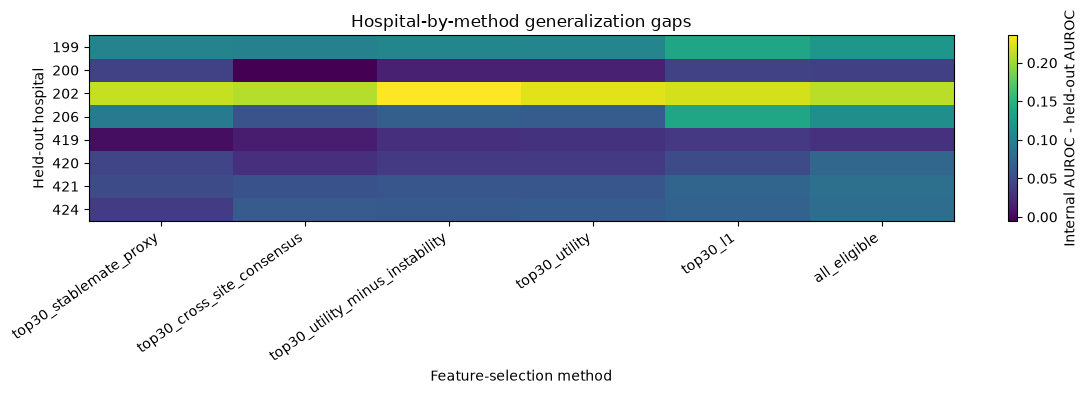

In [14]:
gap_matrix = heldout_perf.pivot(index="hospitalid", columns="method", values="gap_auroc")

plt.figure(figsize=(12, max(4, 0.45 * len(gap_matrix))))
im = plt.imshow(gap_matrix[order].to_numpy(), aspect="auto")
plt.colorbar(im, label="Internal AUROC - held-out AUROC")
plt.yticks(range(len(gap_matrix)), gap_matrix.index.astype(str))
plt.xticks(range(len(order)), order, rotation=35, ha="right")
plt.xlabel("Feature-selection method")
plt.ylabel("Held-out hospital")
plt.title("Hospital-by-method generalization gaps")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gap_heatmap_hospital_by_method.png", dpi=220, bbox_inches="tight")
plt.show()

## 9. Interpretability: utility vs instability and internal vs external tradeoff

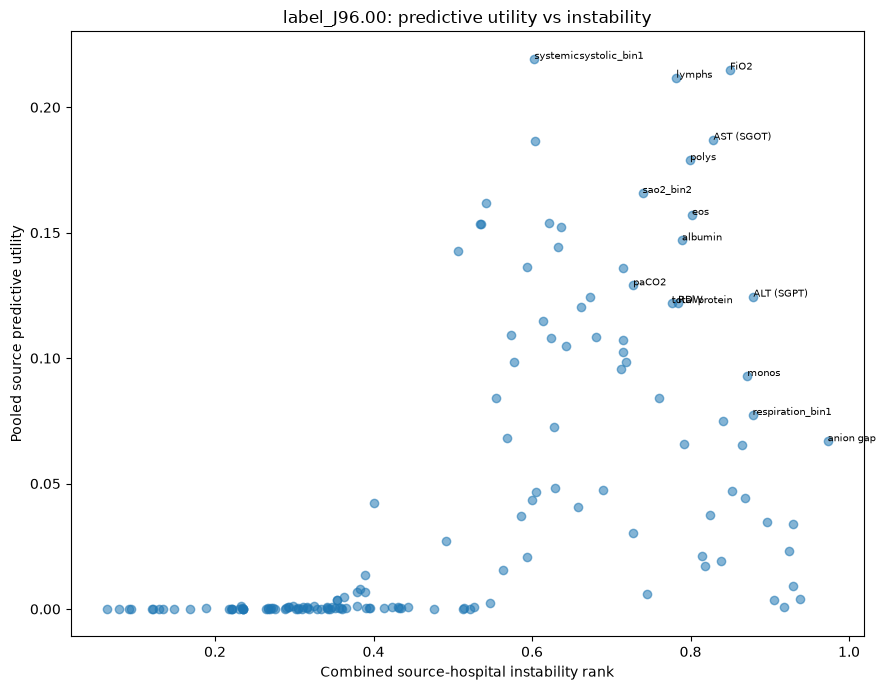

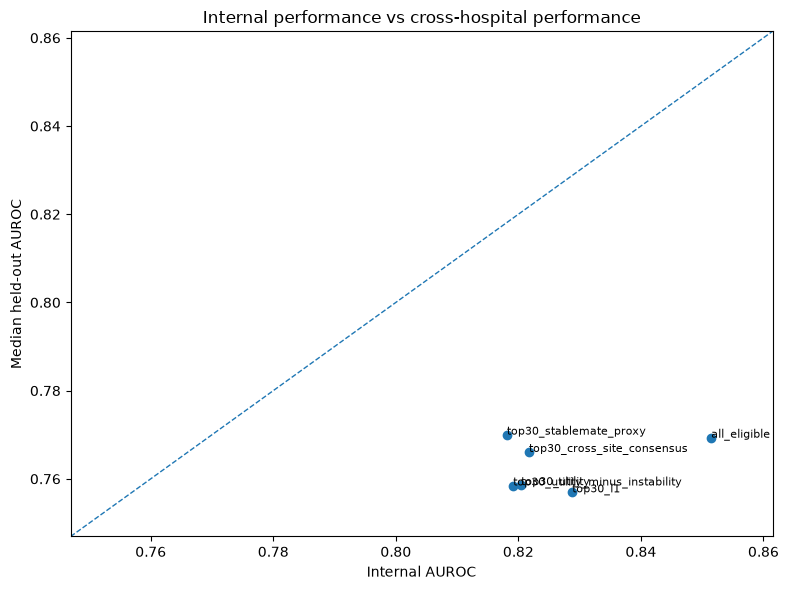

In [15]:
plot_scores = feature_scores.dropna(subset=["predictive_utility", "combined_instability"]).copy()

plt.figure(figsize=(9, 7))
plt.scatter(plot_scores["combined_instability"], plot_scores["predictive_utility"], alpha=0.55)
plot_scores["interesting"] = plot_scores["predictive_utility_rank"] + plot_scores["combined_instability"]
for _, row in plot_scores.sort_values("interesting", ascending=False).head(15).iterrows():
    plt.annotate(row["feature"], (row["combined_instability"], row["predictive_utility"]), fontsize=7)
plt.xlabel("Combined source-hospital instability rank")
plt.ylabel("Pooled source predictive utility")
plt.title(f"{OUTCOME}: predictive utility vs instability")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "utility_vs_instability.png", dpi=220, bbox_inches="tight")
plt.show()

tradeoff = summary.reset_index()
plt.figure(figsize=(8, 6))
plt.scatter(tradeoff["internal_auroc"], tradeoff["median_heldout_auroc"])
for _, row in tradeoff.iterrows():
    plt.annotate(row["method"], (row["internal_auroc"], row["median_heldout_auroc"]), fontsize=8)
lims = [
    min(tradeoff["internal_auroc"].min(), tradeoff["median_heldout_auroc"].min()) - 0.01,
    max(tradeoff["internal_auroc"].max(), tradeoff["median_heldout_auroc"].max()) + 0.01,
]
plt.plot(lims, lims, linestyle="--", linewidth=1)
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Internal AUROC")
plt.ylabel("Median held-out AUROC")
plt.title("Internal performance vs cross-hospital performance")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "internal_vs_heldout_auroc.png", dpi=220, bbox_inches="tight")
plt.show()

## 10. What to conclude before changing the setup

Answer these before trying another split or outcome:

1. Which selector has the smallest median/mean gap?
2. Did it preserve held-out AUROC, or did it merely lower internal AUROC?
3. Do the same hospitals remain difficult across selectors?
4. Which features are selected by the best method but not by pooled utility?
5. Which highly predictive features are removed by stability-aware methods?
6. Are labs/vitals disproportionately removed relative to diagnosis features?
7. Does the source-only utility-vs-instability plot explain the model-level result?

### Robustness checks only after the primary result is recorded
- outcome: `mortality_at48h`;
- another regional transfer;
- another `N_SELECTED`;
- another model class;
- another stability penalty `lambda`.

Do not redefine the primary split after seeing which setup makes a selector look best.

In [16]:
print("Outputs saved to:", OUTPUT_DIR.resolve())
display(summary.round(4))
display(group_counts)

Outputs saved to: /Users/gabrielarm300/Downloads/feature_selection_generalization_outputs


,n_hospitals,n_features,mean_gap,median_gap,worst_gap,median_heldout_auroc,mean_heldout_auroc,median_heldout_auprc,internal_auroc,internal_auprc,internal_brier
method,,,,,,,,,,,
top30_stablemate_proxy,8,30,0.0737,0.0481,0.2143,0.7700,0.7445,0.4239,0.8181,0.1742,0.1776
top30_cross_site_consensus,8,30,0.0651,0.0557,0.2089,0.7661,0.7566,0.4481,0.8217,0.1760,0.1790
top30_utility_minus_instability,8,30,0.0762,0.0607,0.2356,0.7585,0.7429,0.3935,0.8192,0.1818,0.1788
top30_utility,8,30,0.0751,0.0619,0.2252,0.7586,0.7454,0.3947,0.8205,0.1853,0.1786
top30_l1,8,30,0.0956,0.0719,0.2201,0.7569,0.7332,0.4561,0.8288,0.1942,0.1750
all_eligible,8,151,0.0943,0.0822,0.2103,0.7693,0.7572,0.4733,0.8515,0.2228,0.1593


feature_group,admissiondx,demographic,icd10_before24h,labs,vitals
method,,,,,
all_eligible,40,3,40,40,28
top30_cross_site_consensus,0,0,0,18,12
top30_l1,7,1,1,14,7
top30_stablemate_proxy,1,1,1,16,11
top30_utility,0,0,1,15,14
top30_utility_minus_instability,0,0,1,14,15


In [19]:
#PART TWO

In [20]:
import time, warnings
from scipy.stats import spearmanr, mannwhitneyu, fisher_exact, rankdata
from sklearn.metrics import roc_auc_score, average_precision_score

# A hospital must have at least this many positives AND negatives (full data) to be a LOHO test fold.
LOHO_MIN_POS = 20
LOHO_MIN_NEG = 20

# Measuring a feature's effect at the held-out hospital:
TRUTH_MIN_OBS   = 30      # non-missing rows needed
TRUTH_MIN_CLASS = 10      # positives AND negatives needed among those rows

# Per-hospital AUROC for the relationship score (same rule as the earlier notebook):
REL_MIN_OBS = MIN_SOURCE_ENV_N
MIN_HOSP_FOR_SCORE = MIN_SOURCE_HOSPITALS_WITH_FEATURE

N_KS_BINS  = 64           # the fast KS compares binned CDFs (64 quantile bins per feature)
POOL_SIZE  = 60           # stable/unstable sets are drawn from the top-POOL_SIZE utility features ...
SET_SIZE   = 30           # ... and each contains SET_SIZE features (so utility is roughly matched)
MAX_MODEL_FOLDS = None    # e.g. 8 for a quick first pass of Step 5; None = all folds
N_BOOT = 2000             # bootstrap resamples (over hospitals) for confidence intervals

BOOT_RNG = np.random.default_rng(SEED)

DEFS = ["missingness", "distribution", "relationship", "relationship_adj", "combined"]
DEF_LABEL = {
    "missingness":      "Missingness instability (SD of observation rate)",
    "distribution":     "Distribution instability (leave-one-out KS / prevalence gap)",
    "relationship":     "Relationship instability (SD of per-hospital AUROC)",
    "relationship_adj": "Relationship instability, noise-adjusted",
    "combined":         "Combined (rank-average of the first three)",
}
GROUP_COLORS = {"labs": "#4C72B0", "vitals": "#55A868", "icd10_before24h": "#C44E52",
                "admissiondx": "#8172B2", "demographic": "#CCB974", "other": "#999999"}

def boot_ci(values, n_boot=N_BOOT):
    # mean and 95% bootstrap CI, resampling over folds/hospitals
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    if len(v) < 3:
        return np.nan, np.nan, np.nan
    means = BOOT_RNG.choice(v, size=(n_boot, len(v)), replace=True).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(v.mean()), float(lo), float(hi)

def partial_spearman(x, y, z):
    # Spearman correlation of x and y after removing the (rank) linear effect of z
    x, y, z = map(lambda a: np.asarray(a, dtype=float), (x, y, z))
    m = ~(np.isnan(x) | np.isnan(y) | np.isnan(z))
    if m.sum() < 15:
        return np.nan
    rx, ry, rz = rankdata(x[m]), rankdata(y[m]), rankdata(z[m])
    Z = np.c_[np.ones(len(rz)), rz]
    res = lambda a: a - Z @ np.linalg.lstsq(Z, a, rcond=None)[0]
    ex, ey = res(rx), res(ry)
    if ex.std() == 0 or ey.std() == 0:
        return np.nan
    return float(np.corrcoef(ex, ey)[0, 1])

def safe_spearman(x, y, min_n=15):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    m = ~(np.isnan(x) | np.isnan(y))
    if m.sum() < min_n or np.unique(x[m]).size < 2 or np.unique(y[m]).size < 2:
        return np.nan
    return float(spearmanr(x[m], y[m])[0])

## Step 1: Precompute per-hospital statistics (once)

The earlier `compute_feature_scores` loops over every feature and every hospital, which is too slow to repeat 46 times.
Here every per-hospital quantity is computed **once** on `source_train` (the 80% development rows), stored in arrays, and each LOHO fold then only needs
cheap array operations over "all hospitals except *h*".

Definitions (same ideas as before, restricted to the `stability_hospitals`, the Midwest hospitals with enough data):
- **missingness**: SD across hospitals of the observation rate.
- **distribution**: for each hospital, KS distance (continuous) or prevalence gap (binary) between it and the pooled *other* hospitals, averaged. KS here is computed on 64-bin quantile CDFs, which is exact up to binning and lets us drop one hospital from the pool instantly.
- **relationship**: SD across hospitals of the per-hospital AUROC (minus 0.5, which doesn't change the SD).
- **relationship_adj (new)**: the same SD, but with the *expected sampling noise* subtracted (Hanley-McNeil variance of each hospital's AUROC). Small hospitals have noisy AUROCs, so the raw SD partly measures hospital size, and this version removes that.

In [22]:
# ---------- Step 1: per-hospital statistics on the development rows ----------
FEATS = list(candidate_features)
J = len(FEATS)
feat_group = np.array([raw_feature_group.get(f, "other") for f in FEATS])
feat_kind  = np.array([feature_kind(source_train[f]) for f in FEATS])      # 'binary' / 'continuous'

S_ids = list(stability_hospitals)             # hospitals usable for stability statistics
S_pos = {h: i for i, h in enumerate(S_ids)}
G = len(S_ids)

Xdev = source_train[FEATS].to_numpy(dtype=float)
ydev = source_train[OUTCOME].to_numpy(dtype=int)
hdev = source_train["hospitalid"].to_numpy()
dev_idx = {h: np.flatnonzero(hdev == h) for h in S_ids}
n_tot = np.array([len(dev_idx[h]) for h in S_ids], dtype=float)

def auc_var(a, n1, n0):
    # Hanley-McNeil variance of an AUROC estimate (symmetric in a <-> 1-a)
    a = min(max(a, 1 - a), 1 - 1e-6)
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return (a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n0 - 1) * (q2 - a * a)) / (n1 * n0)

n_obs = np.zeros((J, G))            # non-missing count per feature x hospital
sum1  = np.zeros((J, G))            # sum of values (for binary features = number of 1s)
E     = np.full((J, G), np.nan)     # per-hospital AUROC - 0.5
SE2   = np.full((J, G), np.nan)     # sampling variance of that AUROC
edges_list = [None] * J
hist = [None] * J                   # continuous features: (G, n_bins) counts per hospital

t0 = time.time()
for j, f in enumerate(FEATS):
    x = Xdev[:, j]
    ok = ~np.isnan(x)
    if feat_kind[j] == "continuous":
        q = np.unique(np.quantile(x[ok], np.linspace(0, 1, N_KS_BINS + 1)[1:-1]))
        edges_list[j] = q
        H = np.zeros((G, len(q) + 1))
    for g, h in enumerate(S_ids):
        idx = dev_idx[h]
        xg, yg = x[idx], ydev[idx]
        m = ~np.isnan(xg)
        n_obs[j, g] = m.sum()
        if m.sum() == 0:
            continue
        sum1[j, g] = xg[m].sum()
        if feat_kind[j] == "continuous":
            H[g] = np.bincount(np.searchsorted(q, xg[m], side="left"), minlength=len(q) + 1)
        if m.sum() >= REL_MIN_OBS:
            yy = yg[m]
            n1 = int(yy.sum()); n0 = len(yy) - n1
            if n1 >= MIN_SOURCE_ENV_POSITIVES and n0 >= MIN_SOURCE_ENV_NEGATIVES:
                a = roc_auc_score(yy, xg[m])
                E[j, g] = a - 0.5
                SE2[j, g] = auc_var(a, n1, n0)
    if feat_kind[j] == "continuous":
        hist[j] = H
print(f"Precomputed statistics for {J} features x {G} hospitals in {time.time() - t0:.1f}s")

Precomputed statistics for 151 features x 46 hospitals in 3.0s


## Step 1b: Scoring function for any set of "training hospitals"

`score_table(T, row_mask)` returns one row per feature with utility and every instability definition, using **only** hospitals `T` for the instability scores
and only rows in `row_mask` for the pooled utility. Calling it with all hospitals gives the full-data scores. Calling it with all-but-one gives a LOHO fold.

In [23]:
# ---------- Step 1b: scoring ----------
def pct_rank(a):
    return pd.Series(a).rank(pct=True, method="average").to_numpy()

def instability_scores(T):
    # all instability measures using only hospitals at positions T of S_ids
    T = np.asarray(T)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        rate = n_obs[:, T] / n_tot[T][None, :]
        miss = rate.std(axis=1, ddof=0)

        ET = E[:, T]
        nv = (~np.isnan(ET)).sum(axis=1)
        sd = np.nanstd(ET, axis=1, ddof=0)
        mse = np.nanmean(SE2[:, T], axis=1)
        mabs = np.nanmean(np.abs(ET), axis=1)
        mean_e = np.nanmean(ET, axis=1)
        tau = np.sqrt(np.maximum(sd ** 2 - mse, 0.0))
    rel      = np.where(nv >= MIN_HOSP_FOR_SCORE, sd, np.nan)
    rel_adj  = np.where(nv >= MIN_HOSP_FOR_SCORE, tau, np.nan)

    dist = np.full(J, np.nan)
    nT = n_obs[:, T]
    for j in range(J):
        if feat_kind[j] == "binary":
            ng, sg = nT[j], sum1[j, T]
            nr, sr = ng.sum() - ng, sg.sum() - sg
            ok = (ng >= MIN_OBS_PER_HOSPITAL_FOR_FEATURE) & (nr >= MIN_OBS_PER_HOSPITAL_FOR_FEATURE)
            if ok.sum() >= MIN_HOSP_FOR_SCORE:
                dist[j] = np.mean(np.abs(sg[ok] / ng[ok] - sr[ok] / nr[ok]))
        else:
            Hc = np.cumsum(hist[j][T], axis=1)
            rest = Hc.sum(axis=0)[None, :] - Hc
            ng, nr = Hc[:, -1], rest[:, -1]
            ok = (ng >= MIN_OBS_PER_HOSPITAL_FOR_FEATURE) & (nr >= MIN_OBS_PER_HOSPITAL_FOR_FEATURE)
            if ok.sum() >= MIN_HOSP_FOR_SCORE:
                ks = np.abs(Hc[ok] / ng[ok, None] - rest[ok] / nr[ok, None]).max(axis=1)
                dist[j] = ks.mean()
    return dict(missingness=miss, distribution=dist, relationship=rel, relationship_adj=rel_adj,
                effect_train=np.where(nv >= MIN_HOSP_FOR_SCORE, mean_e, np.nan),
                mean_abs_effect=mabs)

def pooled_auc_vec(row_mask):
    # pooled univariate AUROC for each feature on the given development rows
    auc = np.full(J, np.nan)
    y = ydev[row_mask]
    for j in range(J):
        x = Xdev[row_mask, j]
        ok = ~np.isnan(x)
        if ok.sum() >= MIN_FEATURE_NONMISSING_COUNT and np.unique(y[ok]).size == 2:
            auc[j] = roc_auc_score(y[ok], x[ok])
    return auc

def score_table(T, row_mask):
    inst = instability_scores(T)
    auc = pooled_auc_vec(row_mask)
    df = pd.DataFrame({"feature": FEATS, "group": feat_group, "kind": feat_kind,
                       "pooled_auc": auc, "utility": 2 * np.abs(auc - 0.5), **inst})
    ranks = []
    for c in ["missingness", "distribution", "relationship"]:
        df[c + "_rank"] = pct_rank(df[c].to_numpy())
        ranks.append(c + "_rank")
    df["combined"] = np.where(df[ranks].notna().all(axis=1), df[ranks].mean(axis=1), np.nan)
    return df

# ---- full-data scores (all stability hospitals) + sanity check against the earlier notebook ----
full_scores = score_table(np.arange(G), np.ones(len(hdev), dtype=bool))
chk = full_scores.merge(feature_scores[["feature", "predictive_utility", "relationship_instability",
                                        "distribution_instability", "missingness_instability"]], on="feature")
print("Sanity check against the earlier notebook's feature_scores (should be ~0 / ~1):")
print("  max |utility difference|          :", np.nanmax(np.abs(chk.utility - chk.predictive_utility)))
print("  max |relationship difference|     :", np.nanmax(np.abs(chk.relationship - chk.relationship_instability)))
print("  Spearman, distribution (KS binned vs exact):", safe_spearman(chk.distribution, chk.distribution_instability))
print("  Spearman, missingness (stability set vs all hospitals):", safe_spearman(chk.missingness, chk.missingness_instability))
full_scores.head()

Sanity check against the earlier notebook's feature_scores (should be ~0 / ~1):
  max |utility difference|          : 0.0
  max |relationship difference|     : 2.7755575615628914e-17
  Spearman, distribution (KS binned vs exact): 0.9995886996984962
  Spearman, missingness (stability set vs all hospitals): 0.896948119295032


,feature,group,kind,pooled_auc,utility,missingness,distribution,relationship,relationship_adj,effect_train,mean_abs_effect,missingness_rank,distribution_rank,relationship_rank,combined
0,admissiondx_ARDS-adult respiratory distress sy...,admissiondx,binary,0.503905,0.007810,0.0,0.003356,0.012385,0.0,0.004247,0.005412,0.135762,0.483444,0.530612,0.383273
1,admissiondx_Abdomen only trauma,admissiondx,binary,0.499613,0.000773,0.0,0.001467,0.003682,0.0,-0.000100,0.001135,0.135762,0.403974,0.482993,0.340909
2,admissiondx_Abdomen/extremity trauma,admissiondx,binary,0.499992,0.000016,0.0,0.000723,0.000981,0.0,-0.000018,0.000273,0.135762,0.317881,0.346939,0.266860
3,admissiondx_Abdomen/face trauma,admissiondx,binary,0.499944,0.000112,0.0,0.000142,0.000084,0.0,-0.000024,0.000024,0.135762,0.158940,0.068027,0.120910
4,admissiondx_Abdomen/multiple trauma,admissiondx,binary,0.500432,0.000864,0.0,0.001285,0.001936,0.0,0.000217,0.000717,0.135762,0.384106,0.414966,0.311611


## Step 2: LOHO folds and feature-level "transport failure"

For each held-out Midwest hospital *h* and each feature *j*:

- `effect_train` = the average per-hospital (AUROC - 0.5) over the **other** hospitals; its sign is the feature's expected direction.
- `effect_heldout` = the feature's (AUROC - 0.5) at *h*, using all of *h*'s patients.
- **`shortfall`** = |effect_train| - sign * effect_heldout. Positive means the feature was weaker at *h* than expected; larger than |effect_train| means its direction flipped.
- `shortfall_pos` = shortfall clipped at 0 (we care about features that let us down, not ones that happen to do better).
- `flip` = 1 if the feature pointed the wrong way at *h*.
- `obs_shift` / `ks_shift` = how different *h* actually is from the training hospitals in observation rate / value distribution (realized missingness and distribution shift).

All instability scores in a fold are computed **without** hospital *h*, so nothing leaks.

In [24]:
# ---------- Step 2: LOHO feature-level folds ----------
all_h = source_all["hospitalid"].to_numpy()
Xfull = source_all[FEATS].to_numpy(dtype=float)
yfull = source_all[OUTCOME].to_numpy(dtype=int)
full_idx = {h: np.flatnonzero(all_h == h) for h in S_ids}

LOHO_HOSPS = [h for h in S_ids
              if hospital_stats.loc[h, "positives"] >= LOHO_MIN_POS
              and hospital_stats.loc[h, "negatives"] >= LOHO_MIN_NEG]
print(f"{len(LOHO_HOSPS)} hospitals qualify as LOHO test folds (of {G} stability hospitals)")

def heldout_truth(h, T):
    idx = full_idx[h]
    xh, yh = Xfull[idx], yfull[idx]
    e = np.full(J, np.nan); obs = np.full(J, np.nan); ksv = np.full(J, np.nan)
    rateT = n_obs[:, T].sum(axis=1) / n_tot[T].sum()
    for j in range(J):
        m = ~np.isnan(xh[:, j])
        obs[j] = m.mean()
        if m.sum() < TRUTH_MIN_OBS:
            continue
        yy = yh[m]; n1 = int(yy.sum()); n0 = len(yy) - n1
        if n1 >= TRUTH_MIN_CLASS and n0 >= TRUTH_MIN_CLASS:
            e[j] = roc_auc_score(yy, xh[m, j]) - 0.5
        if feat_kind[j] == "binary":
            ksv[j] = abs(xh[m, j].mean() - sum1[j, T].sum() / n_obs[j, T].sum())
        else:
            nb = len(edges_list[j]) + 1
            c = np.bincount(np.searchsorted(edges_list[j], xh[m, j], side="left"), minlength=nb)
            cdf_h = np.cumsum(c) / c.sum()
            cT = np.cumsum(hist[j][T].sum(axis=0)); cdf_T = cT / cT[-1]
            ksv[j] = np.abs(cdf_h - cdf_T).max()
    return e, np.abs(obs - rateT), ksv

fold_cache = {}
t0 = time.time()
for k, h in enumerate(LOHO_HOSPS, 1):
    T = np.array([S_pos[g] for g in S_ids if g != h])
    tab = score_table(T, hdev != h)
    e_h, obs_shift, ks_shift = heldout_truth(h, T)
    s = np.sign(tab["effect_train"].to_numpy())
    s[s == 0] = np.nan
    tab["fold_hosp"] = h
    tab["effect_heldout"] = e_h
    tab["shortfall"] = np.abs(tab["effect_train"]) - s * e_h
    tab["shortfall_pos"] = tab["shortfall"].clip(lower=0)
    tab["flip"] = np.where(np.isnan(s * e_h), np.nan, (s * e_h < 0).astype(float))
    tab["obs_shift"] = obs_shift
    tab["ks_shift"] = ks_shift
    fold_cache[h] = tab
    if k % 10 == 0 or k == len(LOHO_HOSPS):
        print(f"  fold {k}/{len(LOHO_HOSPS)} done ({time.time() - t0:.0f}s)")

loho_scores = pd.concat(fold_cache.values(), ignore_index=True)
loho_scores.to_csv(OUTPUT_DIR / "loho_feature_scores.csv", index=False)

# one row per feature: average transport failure over folds (used to color the scatter plots)
feat_truth = (loho_scores.groupby("feature")
              .agg(truth_shortfall_pos=("shortfall_pos", "mean"),
                   truth_flip=("flip", "mean"),
                   n_folds_truth=("shortfall", "count")))
feat_summary = full_scores.merge(feat_truth, left_on="feature", right_index=True, how="left")
feat_summary.to_csv(OUTPUT_DIR / "feature_summary_utility_instability_truth.csv", index=False)
feat_summary.sort_values("truth_shortfall_pos", ascending=False).head(15)[
    ["feature", "group", "utility", "combined", "relationship", "truth_shortfall_pos", "truth_flip"]]

29 hospitals qualify as LOHO test folds (of 46 stability hospitals)
  fold 10/29 done (5s)
  fold 20/29 done (9s)
  fold 29/29 done (14s)


,feature,group,utility,combined,relationship,truth_shortfall_pos,truth_flip
112,respiration_bin2,vitals,0.034807,0.823279,0.120237,0.056054,0.482759
145,systemicdiastolic_bin2,vitals,0.040626,0.690731,0.081278,0.048850,0.470588
141,systemicmean_bin1,vitals,0.186583,0.629890,0.062623,0.048578,0.166667
130,paO2,labs,0.021111,0.814269,0.100802,0.047823,0.448276
62,respiration_bin1,vitals,0.077365,0.794462,0.102498,0.046915,0.448276
144,systemicmean_bin2,vitals,0.108024,0.653166,0.073202,0.043970,0.294118
143,systemicdiastolic_bin1,vitals,0.104804,0.664324,0.073657,0.042987,0.352941
140,st3_bin2,vitals,0.009039,0.915694,0.097648,0.039461,0.437500
139,st3_bin1,vitals,0.000637,0.924164,0.085868,0.039295,0.444444
120,bicarbonate,labs,0.003650,0.902690,0.107194,0.035842,0.346154


## Step 3: Utility vs. instability scatter plots (one point per feature X_j)

- x = instability, y = predictive utility. Dashed lines mark the **top third** of each axis.
- **Top-left of the high-utility zone** (high utility, low instability) = "highly predictive and transports well".
- **Top-right** (high utility, high instability) = "highly predictive but doesn't transport well" (the risky features for selection).
- Figure 2 repeats the plot colored by the *measured* transport failure from LOHO, so you can check whether the top-right corner really is where features fail.

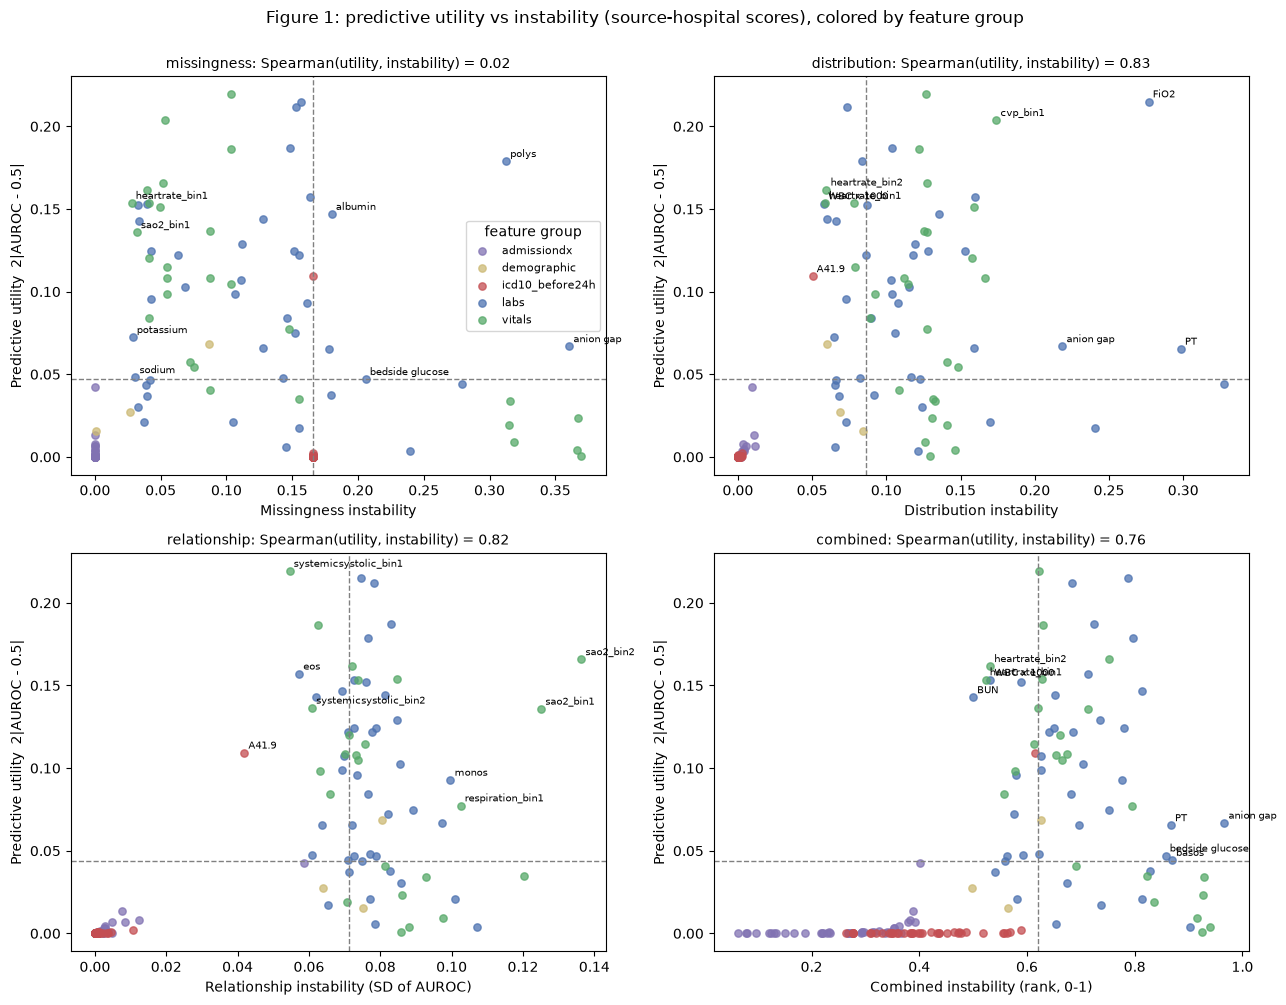

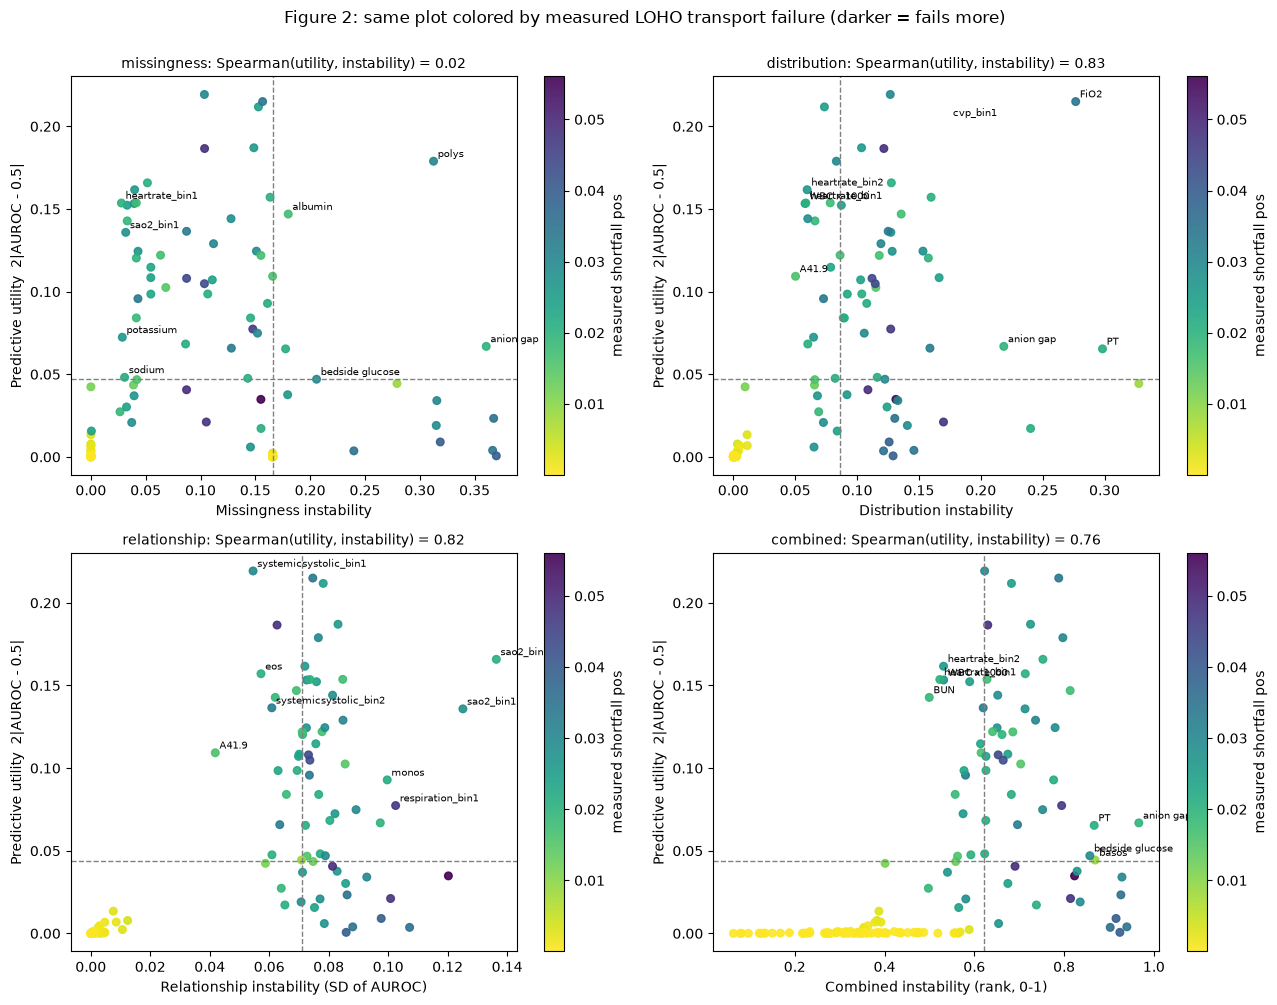

In [26]:
# ---------- Step 3: scatter plots ----------
PANELS = ["missingness", "distribution", "relationship", "combined"]
XLAB = {"missingness": "Missingness instability", "distribution": "Distribution instability",
        "relationship": "Relationship instability (SD of AUROC)", "combined": "Combined instability (rank, 0-1)"}

def scatter_panels(df, color_by=None, fname="fig_utility_vs_instability.png", title=""):
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    for ax, d in zip(axes.ravel(), PANELS):
        sub = df.dropna(subset=["utility", d]).copy()
        ux, ix = sub["utility"].quantile(2 / 3), sub[d].quantile(2 / 3)
        if color_by is None:
            for g, gdf in sub.groupby("group"):
                ax.scatter(gdf[d], gdf["utility"], s=28, alpha=0.75, label=g, color=GROUP_COLORS.get(g, "#999"))
        else:
            sc_df = sub.dropna(subset=[color_by])
            sc = ax.scatter(sc_df[d], sc_df["utility"], c=sc_df[color_by], s=30, cmap="viridis_r", alpha=0.9)
            plt.colorbar(sc, ax=ax, label=color_by.replace("truth_", "measured ").replace("_", " "))
        ax.axvline(ix, ls="--", lw=1, color="gray"); ax.axhline(ux, ls="--", lw=1, color="gray")
        hu = sub[sub["utility"] >= ux]
        for _, r in pd.concat([hu.nsmallest(4, d), hu.nlargest(4, d)]).iterrows():
            ax.annotate(str(r["feature"])[:26], (r[d], r["utility"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
        ax.set_xlabel(XLAB[d]); ax.set_ylabel("Predictive utility  2|AUROC - 0.5|")
        rho = safe_spearman(sub[d], sub["utility"])
        ax.set_title(f"{d}: Spearman(utility, instability) = {rho:.2f}", fontsize=10)
    if color_by is None:
        axes[0, 0].legend(fontsize=8, title="feature group")
    plt.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / fname, dpi=200, bbox_inches="tight")
    plt.show()

scatter_panels(feat_summary, None, "fig1_utility_vs_instability_by_group.png",
               "Figure 1: predictive utility vs instability (source-hospital scores), colored by feature group")
scatter_panels(feat_summary, "truth_shortfall_pos", "fig2_utility_vs_instability_by_transport_failure.png",
               "Figure 2: same plot colored by measured LOHO transport failure (darker = fails more)")